# EMQA_L4_tails

**Large price rises are far more frequent than the normal curve allows**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_tails/EMQA_L4_tails.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
START = pd.Timestamp('2015-01-01')
END = pd.Timestamp('2026-10-31')           # cut-off of Lecture 4: last complete month of the download
CAL = pd.date_range(START, END, freq='D')
P = PD[['RO', 'DE_LU']].reindex(CAL)           # full calendar: missing days stay missing
X = P.diff()                           # daily change X_t = P_t - P_{t-1}; a change next to a gap is missing
print('daily prices', d(START), 'to', d(END), '| missing days in Romania:', int(P['RO'].isna().sum()))

daily prices 2015-01-01 to 2026-10-31 | missing days in Romania: 5


## Heavy tails

Under normality a rise above $\mu+3\sigma$ has probability $1-\Phi(3)\approx 0.00135$; the survival curve of the data lies far above the normal curve.

In [4]:
for z in ['RO', 'DE_LU']:
    show(f'dist.{z}.exkurt', round(stats.kurtosis(X[z].dropna()), 2))
x = X['RO'].dropna()
m, s = x.mean(), x.std()
zmax = (x.max() - m) / s
lp = stats.norm.logsf(zmax) / np.log(10)             # log10 P(Z > zmax) under normality
show('dist.RO.n_3sd_up', int((x > m + 3 * s).sum()))
show('dist.RO.exp_3sd', round(len(x) * stats.norm.sf(3), 2))
show('dist.RO.max_z', round(zmax, 1))
show('dist.RO.max_logyears', int(np.floor(-lp - np.log10(365.25))))

dist.RO.exkurt               = 11.97
dist.DE_LU.exkurt            = 12.1
dist.RO.n_3sd_up             = 52
dist.RO.exp_3sd              = 5.82
dist.RO.max_z                = 10.1
dist.RO.max_logyears         = 20


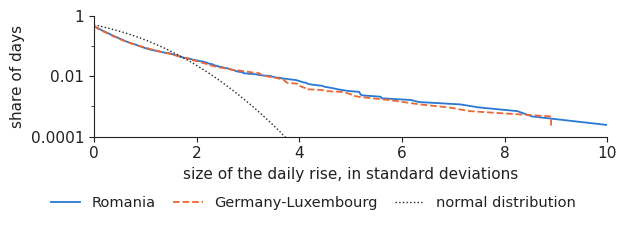

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 2.3))
zz = np.linspace(0, 10, 200)
for z, ls, lab in [('RO', '-', 'Romania'), ('DE_LU', '--', 'Germany-Luxembourg')]:
    s_ = X[z].dropna()
    zs = np.sort(((s_ - s_.mean()) / s_.std()).values)
    surv = 1 - np.arange(1, len(zs) + 1) / (len(zs) + 1)
    sel = zs > 0
    ax.plot(zs[sel], surv[sel], color=PAL[z], ls=ls, lw=1.3, label=lab)
ax.plot(zz, stats.norm.sf(zz), color='#222222', lw=1.0, ls=':', label='normal distribution')
ax.set_yscale('log')
ax.set_ylim(1e-4, 1)
ax.set_xlim(0, 10)
ax.set_xlabel('size of the daily rise, in standard deviations')
ax.set_ylabel('share of days')
ax.set_yticks([1e-4, 1e-2, 1])
ax.set_yticks([1e-3, 1e-1], minor=True)
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_yticklabels(['0.0001', '0.01', '1'])
legend_bottom(fig, ncol=3)
fig.canvas.draw()
legend_top = max(lg.get_window_extent().y1 for lg in fig.legends) / fig.dpi
fig.tight_layout(rect=(0, max(legend_top - 0.08, 0.05) / fig.get_figheight(), 1, 1))
plt.savefig('tails.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()